# 04 — Perceived authenticity in recipe reviews (Word2Vec + KWIC)

**Question:** *Do the recipes whose ingredients are most typical of their cuisine also get called "authentic" by the people who cook them?*

Simple word counting fails on recipe reviews because words like *authentic*, *traditional*, and *real* often appear in negations (*"not authentic"*), store-bought brands (*"Traditional Ragu"*), or generic praise (*"a real hit"*). 
That is why several methods were tested and evaluated. Here the best and simplest approach will be discussed.

A great reference has been a paper named "How consumers perceive authenticity in restaurants: A study of online reviews" by Le et al. (2022) which investigated a similar question of "authenticity" but in the context of restaurant reviews.

Our authenticity labelling can be subdivided in the following two simple steps:

1. **Word2Vec filtering**: Following Le et al., we use a vocabulary constructed via Word2Vec (also including the words already found by Le et al.) to filter all the reviews and keep candidate reviews mentioning both an authenticity term and a recipe attribute.
2. **Multi-rule KWIC**: classify authenticity endorsements with four KWIC checks per review filtered in 1.

We then performed some critical next steps:
-  **Validation**: evaluate precision and recall on 100 hand-labeled test reviews (`test_100.csv`).
-  **Network comparison**: join the authenticity labelled reviews with the ingredient-network and score the results, also run shuffle tests and confirm against an independent pure-embedding check.

at last we define our key findings and limitations of the process.


## 0. Setup and data

loading the data and a few simple numbers, as in the previous notebooks


In [1]:
from pathlib import Path
import html
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.stats import spearmanr

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import authenticity as au

DATA = ROOT / "data" / "processed"
W2V_DIR = DATA / "recipe_word2vec"
SHARE_DIR = DATA / "authenticity_shareable"

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

recipes = pd.read_csv(DATA / "recipes.csv")
reviews = pd.read_csv(DATA / "reviews.csv")
network = pd.read_csv(DATA / "network_recipe_distinctiveness_full.csv")
print(f"Loaded {len(recipes):,} recipes, {len(reviews):,} reviews, and {len(network):,} network-scored recipes.")


Loaded 26,727 recipes, 132,744 reviews, and 26,727 network-scored recipes.


### 0.1 Counting

As a starting point (following the first notebook), we count how often the cleaned reviews contain *authentic* (including *authentically*, *authenticity*, *inauthentic*) and common synonyms (*traditional*, *original*, *real*, *genuine*), and plot *authentic* mentions per 1,000 reviews by cuisine.


,Term,Matching reviews,Share of reviews,Matching recipes
0,authentic*,1318,0.99%,913
1,traditional*,786,0.59%,647
2,original,771,0.58%,614
3,real,2103,1.58%,1481
4,genuine,25,0.02%,25


Reviews mentioning 'authentic*': 1,318 of 132,744 (0.99%), of which 99 contain explicit negation ('not authentic' / 'inauthentic').


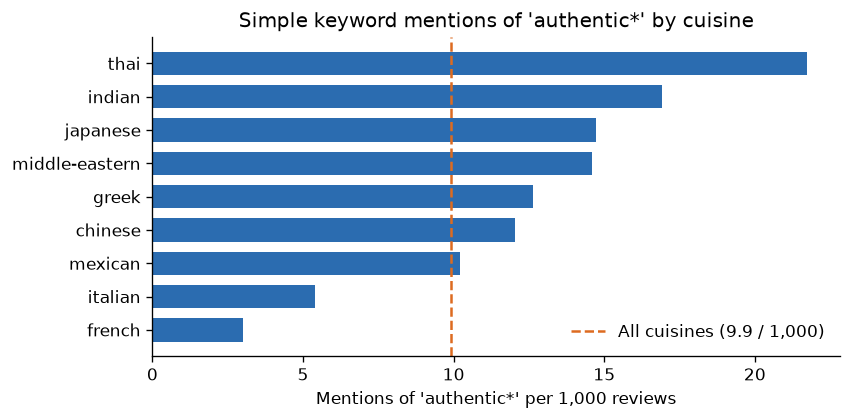

In [2]:
text_lower = reviews["review"].fillna("").map(html.unescape).str.lower()

# Count 'authentic*' and basic synonyms across all 132,744 cleaned reviews
syn_rows = []
for label, pat in [
    ("authentic*", r"\b(?:in)?authentic\w*"),
    ("traditional*", r"\btraditional\w*"),
    ("original", r"\boriginal\b"),
    ("real", r"\breal\b"),
    ("genuine", r"\bgenuine\b"),
]:
    hit = text_lower.str.contains(pat, regex=True)
    syn_rows.append({
        "Term": label,
        "Matching reviews": int(hit.sum()),
        "Share of reviews": f"{hit.mean():.2%}",
        "Matching recipes": int(reviews.loc[hit, "recipe_id"].nunique()),
    })
display(pd.DataFrame(syn_rows))

auth = text_lower.str.contains(r"\b(?:in)?authentic\w*", regex=True)
neg_auth = text_lower.loc[auth].str.contains(r"\b(?:not|isn'?t|wasn'?t|never|hardly)\s+(?:\w+\s+)?authentic|\binauthentic", regex=True).sum()
print(f"Reviews mentioning 'authentic*': {auth.sum():,} of {len(reviews):,} ({auth.mean():.2%}), of which {neg_auth:,} contain explicit negation ('not authentic' / 'inauthentic').")

# Rate per 1,000 reviews by cuisine (matching 01_initial_eda.ipynb)
by_c = (
    reviews.assign(auth=auth)
    .groupby("cuisine")["auth"]
    .agg(reviews="size", mentions="sum", per_1000=lambda s: s.mean() * 1000)
    .sort_values("per_1000")
)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.barh(by_c.index, by_c["per_1000"], color="#2b6cb0", height=0.7)
base = auth.mean() * 1000
ax.axvline(base, color="#dd6b20", ls="--", lw=1.5, label=f"All cuisines ({base:.1f} / 1,000)")
ax.set_xlabel("Mentions of 'authentic*' per 1,000 reviews")
ax.set_title("Simple keyword mentions of 'authentic*' by cuisine")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


Simple keyword counting is not good enough because it treats every occurrence as an endorsement: counting explicit negations (*"not authentic"*), store-bought ingredient names (*"Traditional Ragu"*), and generic praise (*"a real hit"*) alongside genuine authenticity judgments. At the same time, searching only for *authentic* misses the many other words and recipe-specific phrases home cooks use to express authenticity, which motivates the Word2Vec vocabulary screen and clause-level KWIC rules next.


## 1. Word2Vec vocabulary filter

Following Le et al. (2022, §3.1), we trained skip-gram Word2Vec directly on all 132,744 cleaned Food.com reviews (608,802 sentences, 13,380 tokens with count ≥ 5; scripts/recipe_word2vec.py) to expand both Le et al.'s 88 authenticity seeds (top-10 nearest neighbors) and 6 starter recipe-attribute groups (dish, ingredient, preparation, sensory, origin, reference).





```python
from gensim.models import Word2Vec
from gensim.models.word2vec import LineSentence

model = Word2Vec(
    sentences=LineSentence(str(corpus)),
    vector_size=100, window=5, min_count=5,
    sg=1, negative=5, epochs=5, workers=1, seed=42,
)
neighbors = model.wv.most_similar(seed, topn=10)
```

Expanding both lists—just as Le et al. did for restaurant attributes—is necessary because a small hand-written seed list misses Food.com-specific variants, misspellings (like authenic), and regional dish or ingredient names (like biryani or tzatziki). After curating the learned neighbors into lexicon.csv, Word2Vec added 10 authenticity terms and 187 recipe-attribute words. Following Le et al. (§3.1), we then keep only reviews with at least one sentence containing both an authenticity term and a recipe attribute, anchoring broad seeds (real, true, careful) to the food rather than conversational filler (e.g., "a real hit with my kids"). 

It's important to note how applying this requirement of having both a recipe element and an authenticity term this is the first step to ensure the review is such that the authenticity is referred to the recipe being reviewd and not just including other recipes.

This narrows the corpus 18× to 7,281 candidate reviews (5.48%) across 4,295 recipes.


In [3]:
pd.set_option("display.max_colwidth", None)
lexicon = pd.read_csv(W2V_DIR / "lexicon.csv")
neighbors = pd.read_csv(W2V_DIR / "neighbors.csv")

# Table 1: Authenticity synonyms / variants added by Word2Vec
w2v_auth = set(lexicon.query("category == 'authenticity' and source == 'word2vec'")["token"])
auth_tbl = (
    neighbors.query("category == 'authenticity' and neighbor in @w2v_auth")
    .sort_values("cosine", ascending=False)
    .drop_duplicates("neighbor")[["neighbor", "seed", "cosine"]]
    .rename(columns={"neighbor": "Added term", "seed": "Nearest seed", "cosine": "Cosine similarity"})
    .assign(**{"Cosine similarity": lambda d: d["Cosine similarity"].round(3)})
    .reset_index(drop=True)
)
print("Table 1 — Authenticity synonyms / variants added by Word2Vec (10 terms):")
display(auth_tbl)

# Table 2: The 6 expanded recipe-attribute groups
attr_rows = []
for cat, grp in lexicon[lexicon["category"] != "authenticity"].groupby("category"):
    seeds = sorted(grp.query("source == 'seed'")["token"].tolist())
    added = sorted(grp.query("source == 'word2vec'")["token"].tolist())
    attr_rows.append({
        "Attribute group": cat,
        "Seed words": len(seeds),
        "Word2Vec added": len(added),
        "Example Word2Vec additions": ", ".join(added[:8]) + ("..." if len(added) > 8 else ""),
    })
print("\nTable 2 — Expanded recipe-attribute groups (6 groups, 187 terms added by Word2Vec):")
display(pd.DataFrame(attr_rows))

filtered = pd.read_csv(W2V_DIR / "dictionary_matched_full_reviews.csv")
print(f"\nStage-1 Word2Vec screen: {len(filtered):,} candidate reviews ({len(filtered)/len(reviews):.2%}) across {filtered['recipe_id'].nunique():,} recipes.")


Table 1 — Authenticity synonyms / variants added by Word2Vec (10 terms):


,Added term,Nearest seed,Cosine similarity
0,recreate,replicate,0.860
1,duplicate,replicate,0.849
2,speciality,specialty,0.837
3,homeade,home_made,0.832
4,reproduce,replicate,0.775
5,authentically,authentic,0.759
6,imitate,replicate,0.720
7,authenic,authentic,0.696
8,clone,classic,0.657
9,copycat,original,0.593



Table 2 — Expanded recipe-attribute groups (6 groups, 187 terms added by Word2Vec):


,Attribute group,Seed words,Word2Vec added,Example Word2Vec additions
0,dish,13,57,"bisque, breadsticks, bruschetta, burrito, burritos, casserole, chapati, chimichangas..."
1,ingredient,10,33,"basmati, beef, bulgur, cayenne, cheddar, cheeses, chickpeas, couscous..."
2,origin,17,37,"american, arabian, arabic, asian, balkan, basque, cantonese, caribbean..."
3,preparation,6,19,"broiling, browning, caramelizing, deglazing, dredging, folding, marination, methods..."
4,reference,5,23,"aunt, bakery, cafe, dad, father, grandfather, grandma, grandmas..."
5,sensory,4,18,"aftertaste, aromas, chewiness, consistency, creaminess, crispness, crunch, flavors..."



Stage-1 Word2Vec screen: 7,281 candidate reviews (5.48%) across 4,295 recipes.


In [4]:
# Three concrete examples illustrating what Stage 1 passes vs. rejects
test_ref = pd.read_csv(SHARE_DIR / "test_100.csv")
ex_pass_pos = test_ref[test_ref["manual_label"].astype(bool) & test_ref["full_review"].str.contains("authentic", case=False, na=False)].iloc[0]["full_review"]
ex_pass_neg = test_ref[~test_ref["manual_label"].astype(bool) & test_ref["full_review"].str.contains("Traditional|not the traditional", case=False, na=False)].iloc[0]["full_review"]
rejected = reviews[~reviews["review_id"].isin(set(filtered["review_id"]))]
ex_rejected = rejected[rejected["review"].str.contains(r"\breal hit\b", case=False, na=False)].iloc[0]["review"]

def clip(s, n=180):
    flat = " ".join(html.unescape(str(s)).split())
    return flat[:n] + ("..." if len(flat) > n else "")

print("\nThree concrete examples of the Stage-1 Word2Vec filter:")
display(pd.DataFrame([
    {"Outcome": "1. Passed & authentic endorsement", "Example review": clip(ex_pass_pos)},
    {"Outcome": "2. Passed, but NOT an endorsement", "Example review": clip(ex_pass_neg)},
    {"Outcome": "3. Rejected by Word2Vec filter", "Example review": clip(ex_rejected)},
]))



Three concrete examples of the Stage-1 Word2Vec filter:


,Outcome,Example review
0,1. Passed & authentic endorsement,Thank you for putting up an authentic recipe!
1,"2. Passed, but NOT an endorsement","Absolutely delicious! They were perfectly flavored and honestly, I did not have the time to make the homemade sauce, so I just simmered the meatballs in ""Traditional"" Ragu sauce an..."
2,3. Rejected by Word2Vec filter,I made these for my husbands birthday. They were a real hit. I did double the cabbage and used a little extra shrimp. Thanks for the recipe.


The next steps focus on filtering out the second kind of review—those that pass the Word2Vec screen without actually endorsing the recipe—which is hard because the exact same authenticity words appear in negations, store-bought ingredient names, suggested recipe edits, and comparisons to other dishes.


## 2. Clause-level KWIC rules

- **Why KWIC:** Checking each authenticity keyword inside its surrounding clause (split on `. ! ? ;` and `but`) lets us separate genuine endorsements (*"authentic Mexican flavor"*) from negations (*"not authentic"*) and suggested edits (*"to make it more authentic, substitute..."*) transparently, without a black-box model.
- **Why 4 rules:** Le et al. (2022, Fig. 1) group authenticity into *Self* (atmosphere), *Producer* (service), and **Other** (*conformity*, *deviation*, *connection*). Since recipes only have ingredients and steps, **Rules 1–3** map directly to those three *Other* cues. **Rule 4** comes from checking the top collocations before *authentic*: edit phrases like *"more authentic"* (84 occurrences) appear more than twice as often as explicit negations like *"not authentic"* (34), so excluding them prevents suggested recipe edits from being counted as endorsements (Section 3.1).
- **How they are combined:** A review is classified as an **endorsement** when a positive cue fires (**Rule 1** or **Rule 3**) and is **not blocked** by an exclusion rule (**Rule 2** for negation, or **Rule 4** for suggested recipe edits).


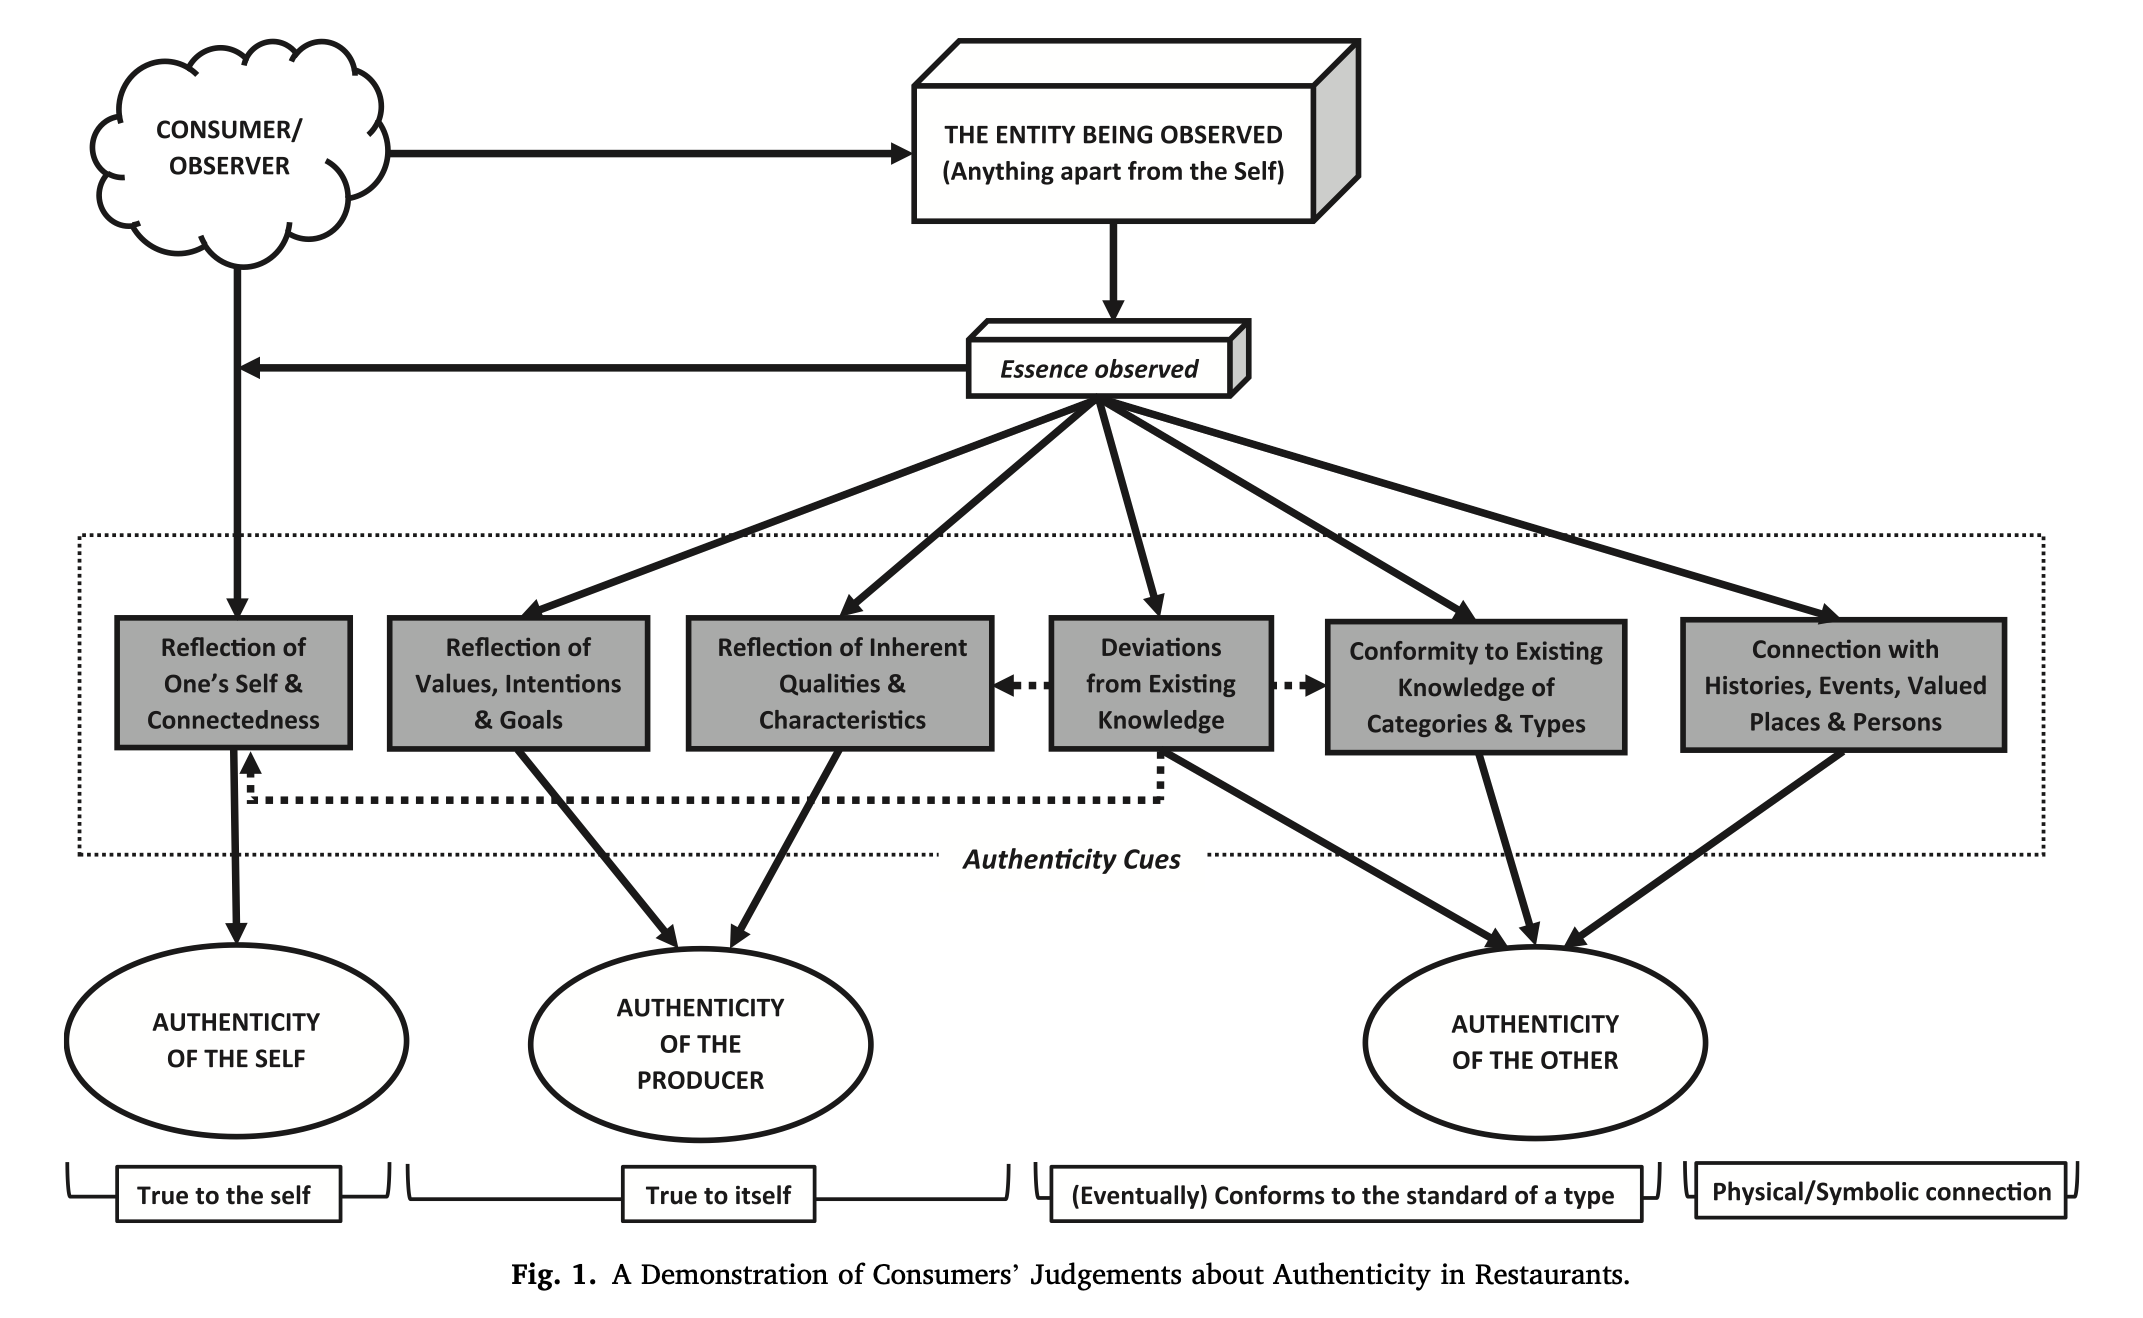

In [5]:
display(Image(filename=str(ROOT / "figures/le2022_page8_themes.png"), width=700))

### From the framework to four rules

The figure above gives the original themes from the paper. The table below translates them into cues that can be checked in a recipe review.

In [5]:
pd.set_option("display.max_colwidth", None)
rules_df = pd.DataFrame([
    {"Rule": "1. Conformity", "Effect": "Endorse", "What it matches (in a clause)": "authentic*, traditional*, genuine, real thing, real deal"},
    {"Rule": "2. Deviation", "Effect": "Block", "What it matches (in a clause)": "Negation within 7 words before the cue (not, never, lacks, far from, n't)"},
    {"Rule": "3. Connection", "Effect": "Endorse", "What it matches (in a clause)": "just like, reminds me of, tastes like / close to the original"},
    {"Rule": "4. Recipe edits", "Effect": "Block", "What it matches (in a clause)": "more authentic, instead of, substitute, next time, would/could/should"},
])
display(rules_df)

,Rule,Effect,What it matches (in a clause)
0,1. Conformity,Endorse,"authentic*, traditional*, genuine, real thing, real deal"
1,2. Deviation,Block,"Negation within 7 words before the cue (not, never, lacks, far from, n't)"
2,3. Connection,Endorse,"just like, reminds me of, tastes like / close to the original"
3,4. Recipe edits,Block,"more authentic, instead of, substitute, next time, would/could/should"


### 2.1 Reading a keyword in context

Read across each row as a single excerpt. In the first, *authentic* describes a friend. In the second, it describes the curry. The same keyword can point to different subjects.

In [5]:
def kwic_sample(series, word="authentic", width=38, n=4, seed=7):
    pat = re.compile(rf"\b{word}\w*\b", re.I)
    rows = []
    for txt in series.sample(frac=1, random_state=seed):
        flat = " ".join(html.unescape(str(txt)).split())
        m = pat.search(flat)
        if m:
            rows.append({
                "Left context": flat[max(0, m.start() - width):m.start()].rjust(width),
                "Keyword": m.group(0),
                "Right context": flat[m.end():m.end() + width],
            })
            if len(rows) >= n:
                break
    return pd.DataFrame(rows)

print("\nSample KWIC concordances around 'authentic':")
display(kwic_sample(filtered["full_review"]))



Sample KWIC concordances around 'authentic':


,Left context,Keyword,Right context
0,My,authentic,Mexican friend born in authentic Mexi
1,This recipe creates an,authentic,"Indian curry, which I was looking for"
2,", but, I assure you, this soup was so",authentic,"and satisfying, even with our flub up"
3,"ecipe, this sauce is great and tastes",authentic,". My husband likes them too, and reque"


## 3. How accurately do the rules identify endorsements?

Of 100 hand-labeled reviews, 22 endorse a recipe. The dictionary finds 19 of those 22, but also flags 33 reviews the annotator labeled negative. The four KWIC rules find 16 of the 22 and flag only 3 negatives.

**Precision** measures how often a flagged review is an endorsement (16 of 19 for KWIC). **Recall** measures how many labeled endorsements the rules recover (16 of 22).

In [6]:
test_df = pd.read_csv(SHARE_DIR / "test_100.csv")[["recipe_id", "review_id", "full_review", "manual_label"]].copy()

def kwic_predict(texts):
    f = au.kwic_flags(texts)
    return (f[:, 0] == 1) | (f[:, 3] == 1)

def eval_metrics(name, y_true, y_pred):
    y, p = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    tp, fp, fn, tn = int((y & p).sum()), int((~y & p).sum()), int((y & ~p).sum()), int((~y & ~p).sum())
    pr = tp / (tp + fp) if (tp + fp) else 0.0
    rc = tp / (tp + fn) if (tp + fn) else 0.0
    return {"Method (test_100)": name, "Reviews": len(y), "Labeled Endorsements": int(y.sum()),
            "True Positives": tp, "False Positives": fp, "False Negatives": fn, "True Negatives": tn,
            "Precision": round(pr, 3), "Recall": round(rc, 3)}

test_df["kwic_pred"] = kwic_predict(test_df["full_review"])
naive_test = test_df["full_review"].str.contains(r"\b(?:authentic\w*|traditional\w*|genuine|real|original)\b", case=False, regex=True)

display(pd.DataFrame([
    eval_metrics("KWIC rules (chosen: Rules 1-4)", test_df["manual_label"], test_df["kwic_pred"]),
    eval_metrics("Naive dictionary (no negation/clause rules)", test_df["manual_label"], naive_test),
]))

,Method (test_100),Reviews,Labeled Endorsements,True Positives,False Positives,False Negatives,True Negatives,Precision,Recall
0,KWIC rules (chosen: Rules 1-4),100,22,16,3,6,75,0.842,0.727
1,Naive dictionary (no negation/clause rules),100,22,19,33,3,45,0.365,0.864


### Examples from the labeled sample

Each row pairs the human label with the KWIC prediction. The excerpts show the first three reviews from each human-label group.

In [6]:
print("\nSample of held-out TEST reviews (3 positive, 3 negative):")
sample = pd.concat([
    test_df[test_df["manual_label"].astype(bool)].head(3),
    test_df[~test_df["manual_label"].astype(bool)].head(3),
])[["recipe_id", "manual_label", "kwic_pred", "full_review"]].copy()
sample["full_review"] = sample["full_review"].map(lambda s: " ".join(html.unescape(s).split())[:130] + "...")
display(sample)



Sample of held-out TEST reviews (3 positive, 3 negative):


,recipe_id,manual_label,kwic_pred,full_review
0,166030,1,True,The perfect mixture for that traditional taco taste. No need to buy that packaged stuff. I used it for recipe #160564 and it was g...
1,47453,1,True,Thank you for putting up an authentic recipe!...
7,142306,1,True,This is an Authentic recipe that I and my husband use. We're from Michocan Mexico. But we prefer Queso Fresco crumbled on top with...
2,8745,0,False,wonderful I Dont' think i will ever make original enchiladas again. We are died in the wool Texans so everyone turned tier noses u...
3,31717,0,False,"I halved this recipe for my smaller crock pot. I also veganized it (using tvp for the ground beef and made my own veggie ""beefish""..."
4,88348,0,False,I made a vegetarian version of the soup by replacing the chicken with beans and a bit of chopped veggies. Even with the substituti...


### 3.1 What does the recipe-edit rule (4) contribute?

Compare three versions on the same 100 reviews. The three-rule version allows suggested edits to count toward endorsement. The four-rule version screens for those edits. The five-rule version also accepts broader references to family or restaurants.

,Method (test_100),Reviews,Labeled Endorsements,True Positives,False Positives,False Negatives,True Negatives,Precision,Recall
0,test_100 | 3 rules (no Rule 4 edit filter),100,22,17,8,5,70,0.680,0.773
1,test_100 | 4 rules (chosen: Rules 1-4),100,22,16,3,6,75,0.842,0.727
2,test_100 | 5 rules (+ broad restaurant/family ref),100,22,18,5,4,73,0.783,0.818


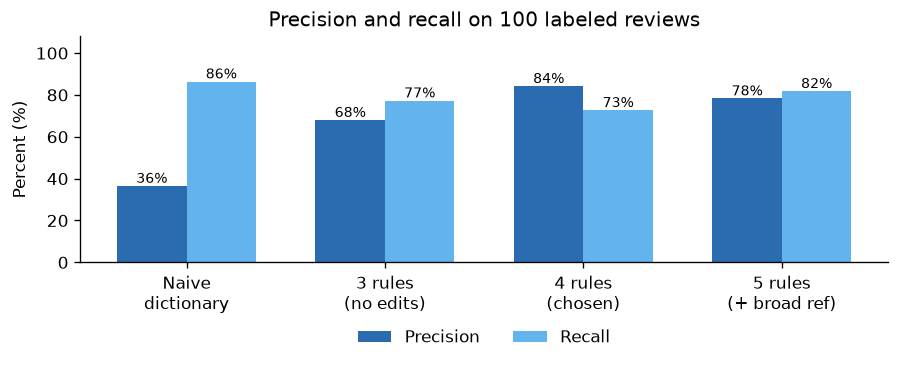

In [7]:
CUE = re.compile(r"\b(?:authentic\w*|traditional\w*|genuine|real thing|real deal)\b")
NEG = re.compile(r"\b(?:not|never|no|hardly|lacks?|lacked|without|anything but|far from)\b|n.t\b")
CHANGE = re.compile(r"\b(?:more authentic|instead of|substitut\w*|would|could|should|next time|to make it more)\b")
RESEMBLANCE = re.compile(r"\b(?:just like|exactly like|reminds me of|tastes? like the original|close to the original)\b")
BROAD_REF = re.compile(r"\b(?:restaurant|grandmother|grandma|nonna|abuela|back home|grew up|way my)\b")

def predict_3_4_5(texts):
    r3, r4, r5 = [], [], []
    for text in texts:
        t = html.unescape(str(text)).lower().replace("’", "'")
        f_no_mod = f_with_mod = f_resem = f_broad = False
        for clause in re.split(r"[.!?;]|\bbut\b", t):
            for cue in CUE.finditer(clause):
                before = " ".join(clause[:cue.start()].split()[-7:])
                neg = bool(NEG.search(before))
                chg = bool(CHANGE.search(clause))
                if not neg:
                    f_no_mod = True
                if not (neg or chg):
                    f_with_mod = True
            if RESEMBLANCE.search(clause) and not NEG.search(clause):
                f_resem = True
            if BROAD_REF.search(clause) and not NEG.search(clause):
                f_broad = True
        r3.append(f_no_mod or f_resem)
        r4.append(f_with_mod or f_resem)
        r5.append(f_with_mod or f_resem or f_broad)
    return np.array(r3), np.array(r4), np.array(r5)

rows_345 = []
for split_name, df_s in [("test_100", test_df)]:
    p3, p4, p5 = predict_3_4_5(df_s["full_review"])
    for lbl, p in [
        ("3 rules (no Rule 4 edit filter)", p3),
        ("4 rules (chosen: Rules 1-4)", p4),
        ("5 rules (+ broad restaurant/family ref)", p5),
    ]:
        rows_345.append(eval_metrics(f"{split_name} | {lbl}", df_s["manual_label"], p))

display(pd.DataFrame(rows_345))

# Visual comparison: Precision vs Recall across Naive, 3, 4 (chosen), and 5 rules on test_100
cmp_df = pd.DataFrame([
    eval_metrics("Naive\ndictionary", test_df["manual_label"], naive_test),
    eval_metrics("3 rules\n(no edits)", test_df["manual_label"], p3),
    eval_metrics("4 rules\n(chosen)", test_df["manual_label"], p4),
    eval_metrics("5 rules\n(+ broad ref)", test_df["manual_label"], p5),
])
x = np.arange(len(cmp_df))
w = 0.35
fig, ax = plt.subplots(figsize=(7.6, 3.3))
b1 = ax.bar(x - w/2, cmp_df["Precision"] * 100, width=w, color="#2b6cb0", label="Precision")
b2 = ax.bar(x + w/2, cmp_df["Recall"] * 100, width=w, color="#63b3ed", label="Recall")
for bars in (b1, b2):
    for bar in bars:
        v = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(cmp_df["Method (test_100)"])
ax.set_ylim(0, 108)
ax.set_ylabel("Percent (%)")
ax.set_title("Precision and recall on 100 labeled reviews")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.23), ncol=2)
plt.tight_layout()
plt.show()


The edit rule removes five false positives at the cost of one true endorsement. Adding the broader reference rule recovers two endorsements and adds two false positives. We use four rules for the remaining analysis because they give the highest precision on this sample (84.2%).

## 4. From review labels to recipe labels

The vocabulary screen retained **7,281 reviews of 4,295 recipes**. We apply the four rules to each review, then count a recipe as endorsed if **at least one** of its screened reviews qualifies. A recipe with several screened reviews therefore has more opportunities to qualify.

In [8]:
filtered["kwic_endorsed"] = kwic_predict(filtered["full_review"])
n_pos_rev = int(filtered["kwic_endorsed"].sum())
n_pos_rec = int(filtered.loc[filtered["kwic_endorsed"], "recipe_id"].nunique())
n_tot_rec = int(filtered["recipe_id"].nunique())

print(f"Reviews classified: {len(filtered):,}")
print(f"  Endorsed reviews:     {n_pos_rev:,} ({n_pos_rev/len(filtered):.1%})")
print(f"  Non-endorsed reviews: {len(filtered) - n_pos_rev:,} ({1 - n_pos_rev/len(filtered):.1%})")
print(f"Recipes covered:    {n_tot_rec:,}")
print(f"  Endorsed recipes:     {n_pos_rec:,} ({n_pos_rec/n_tot_rec:.1%})")
print(f"  Non-endorsed recipes: {n_tot_rec - n_pos_rec:,} ({1 - n_pos_rec/n_tot_rec:.1%})")


Reviews classified: 7,281
  Endorsed reviews:     1,518 (20.8%)
  Non-endorsed reviews: 5,763 (79.2%)
Recipes covered:    4,295
  Endorsed recipes:     1,074 (25.0%)
  Non-endorsed recipes: 3,221 (75.0%)


## 5. Do endorsed recipes use more characteristic ingredient pairs?

Of the 4,295 recipes with screened reviews, **4,275** also have a network pairing score. Notebook 03 supplies three measures for this comparison.

| Measure | What it captures |
| --- | --- |
| `ingredient_distinctiveness` | How typical the individual ingredients are of the cuisine |
| `pair_distinctiveness` | How typical the ingredient pairs are, before adjusting for the popularity of each ingredient |
| `pairing_score` | How strongly ingredients occur together beyond what their separate popularity predicts |

### 5.1 Endorsement rates across pairing scores

We rank recipes **within each cuisine** and divide them into four equally sized groups, as closely as possible. The left panel pools the groups across cuisines. The right panel shows the rank correlation for each cuisine separately.

,pairing_q,recipes,endorsed,endorsement_rate
0,Q1 (lowest 25%),1073,215,20.0%
1,Q2,1067,233,21.8%
2,Q3,1067,274,25.7%
3,Q4 (highest 25%),1068,348,32.6%


Top 10% vs Bottom 10% of pairing_score (KWIC): 18.3% -> 32.6% (1.78x)


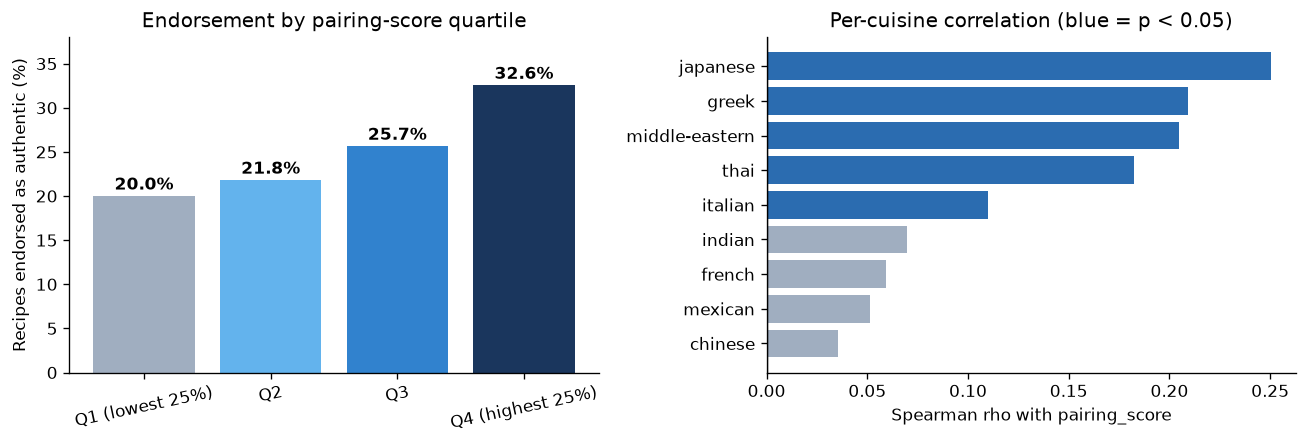

In [9]:
recipe_preds = filtered.groupby("recipe_id").agg(
    matched_reviews=("review_id", "size"),
    kwic_endorsed=("kwic_endorsed", "any"),
).reset_index()

m = (
    network.merge(recipe_preds, on="recipe_id", how="inner")
    .dropna(subset=["pairing_score"])
    .reset_index(drop=True)
)
m["y_kwic"] = m["kwic_endorsed"].astype(int)
m["pairing_q"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 4, labels=["Q1 (lowest 25%)", "Q2", "Q3", "Q4 (highest 25%)"])
)
m["pairing_d"] = m.groupby("cuisine")["pairing_score"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
)

q_df = m.groupby("pairing_q", observed=False).agg(
    recipes=("recipe_id", "size"), endorsed=("y_kwic", "sum"), endorsement_rate=("y_kwic", "mean")
).reset_index()
display(q_df.assign(endorsement_rate=lambda d: d["endorsement_rate"].map("{:.1%}".format)))

d_kw = m.groupby("pairing_d", observed=False)["y_kwic"].mean()
print(f"Top 10% vs Bottom 10% of pairing_score (KWIC): {d_kw.iloc[0]:.1%} -> {d_kw.iloc[-1]:.1%} ({d_kw.iloc[-1]/d_kw.iloc[0]:.2f}x)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 3.8))
ax1.bar(q_df["pairing_q"], q_df["endorsement_rate"] * 100, color=["#a0aec0", "#63b3ed", "#3182ce", "#1a365d"])
for i, v in enumerate(q_df["endorsement_rate"] * 100):
    ax1.text(i, v + 0.7, f"{v:.1f}%", ha="center", fontweight="bold")
ax1.set_ylim(0, 38)
ax1.set_ylabel("Recipes endorsed as authentic (%)")
ax1.set_title("Endorsement by pairing-score quartile")
ax1.tick_params(axis="x", rotation=12)

c_rows = []
for c, g in m.groupby("cuisine"):
    r, p = spearmanr(g["y_kwic"], g["pairing_score"])
    c_rows.append({"cuisine": c, "n": len(g), "endorsed": int(g["y_kwic"].sum()), "rho": r, "p": p})
c_df = pd.DataFrame(c_rows).sort_values("rho")
colors = ["#2b6cb0" if p < 0.05 else "#a0aec0" for p in c_df["p"]]
ax2.barh(c_df["cuisine"], c_df["rho"], color=colors)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_xlabel("Spearman rho with pairing_score")
ax2.set_title("Per-cuisine correlation (blue = p < 0.05)")
plt.tight_layout()
plt.show()


**Endorsement rises from 20.0% in the lowest quartile to 32.6% in the highest**, a gap of 12.6 percentage points. All nine cuisines show a positive correlation. Five have individual, unadjusted $p < 0.05$: Japanese, Greek, Middle Eastern, Thai and Italian.

### 5.2 Does the association survive three checks?

1. **Chance within cuisines.** Shuffle labels within each cuisine 2,000 times and compare the observed correlation with the shuffled correlations.
2. **Review count.** Repeat the pairing test for the 3,214 recipes with exactly one screened review each.
3. **Choice of classifier.** Compare KWIC with binary and continuous scores from the GTE embedding model on the same matched recipes.

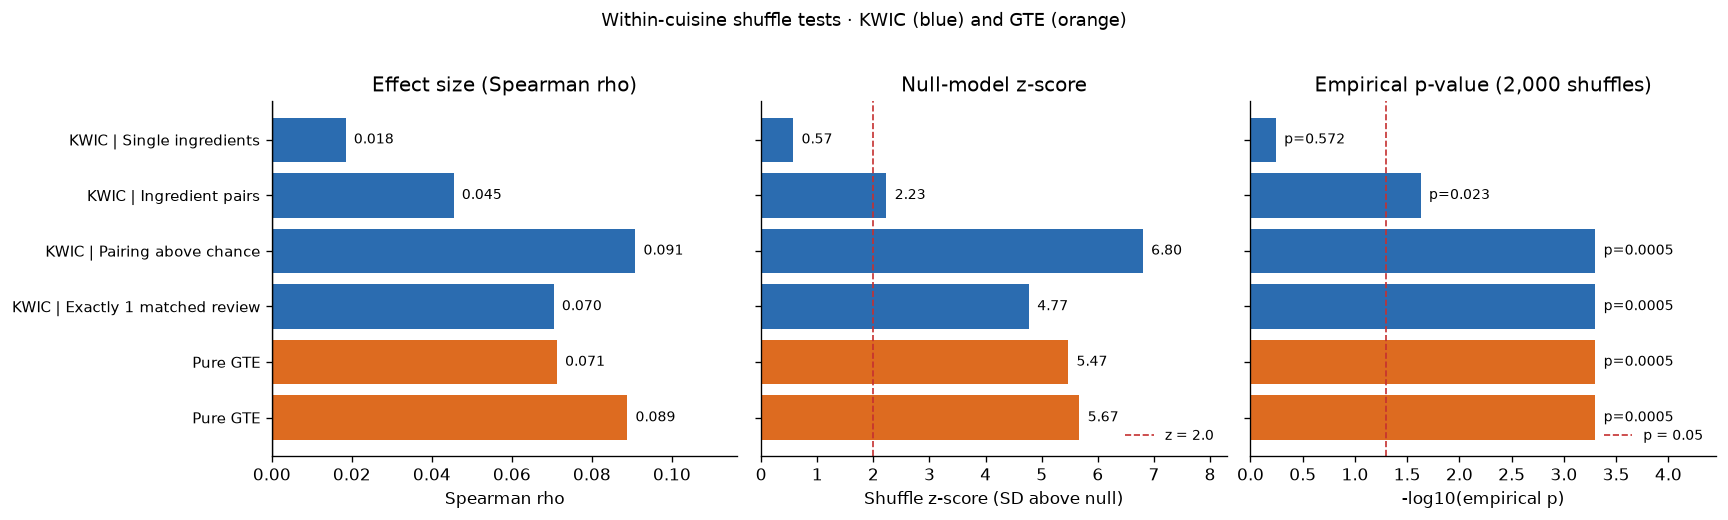

In [10]:
# Week 2 label-shuffle null tests (2,000 permutations) for KWIC + Pure GTE confirmation (scripts/pure_gte_check.py)
one_rev = m[m["matched_reviews"] == 1]

tests = [
    ("KWIC | Single ingredients (ingredient_distinctiveness)", m, "y_kwic", "ingredient_distinctiveness", ["cuisine"]),
    ("KWIC | Ingredient pairs (pair_distinctiveness)", m, "y_kwic", "pair_distinctiveness", ["cuisine"]),
    ("KWIC | Pairing above chance (pairing_score)", m, "y_kwic", "pairing_score", ["cuisine"]),
    ("KWIC | Exactly 1 matched review (review-count check)", one_rev, "y_kwic", "pairing_score", ["cuisine"]),
]
kwic_shuf = pd.DataFrame([{"test": lbl, **au.shuffle_test(sub, yc, xc, st, n_perm=2000, seed=42)} for lbl, sub, yc, xc, st in tests])
gte_shuf = pd.read_csv(W2V_DIR / "pure_gte_shuffle_summary.csv")
shuf_df = pd.concat([kwic_shuf, gte_shuf], ignore_index=True)

# 3-panel visual chart of Spearman rho, z-score, and empirical p-value (KWIC main + Pure GTE confirmation)
plot_df = shuf_df.iloc[::-1].reset_index(drop=True)
y_idx = np.arange(len(plot_df))
bar_colors = ["#dd6b20" if t.startswith("Pure GTE") else "#2b6cb0" for t in plot_df["test"]]

fig, (ax_r, ax_z, ax_p) = plt.subplots(1, 3, figsize=(14.5, 4.2), sharey=True)

ax_r.barh(y_idx, plot_df["obs_rho"], color=bar_colors)
ax_r.axvline(0, color="black", linewidth=0.8)
for i, v in enumerate(plot_df["obs_rho"]):
    ax_r.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5)
ax_r.set_xlim(0, max(plot_df["obs_rho"]) * 1.28)
ax_r.set_yticks(y_idx)
ax_r.set_yticklabels(plot_df["test"].str.replace(r" \(.*?\)$", "", regex=True), fontsize=9)
ax_r.set_xlabel("Spearman rho")
ax_r.set_title("Effect size (Spearman rho)")

ax_z.barh(y_idx, plot_df["z_score"], color=bar_colors)
ax_z.axvline(2.0, color="#c53030", linestyle="--", linewidth=1.0, label="z = 2.0")
for i, v in enumerate(plot_df["z_score"]):
    ax_z.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8.5)
ax_z.set_xlim(0, max(plot_df["z_score"]) * 1.22)
ax_z.set_xlabel("Shuffle z-score (SD above null)")
ax_z.set_title("Null-model z-score")
ax_z.legend(frameon=False, loc="lower right", fontsize=8.5)

neg_log_p = -np.log10(plot_df["empirical_p"])
ax_p.barh(y_idx, neg_log_p, color=bar_colors)
ax_p.axvline(-np.log10(0.05), color="#c53030", linestyle="--", linewidth=1.0, label="p = 0.05")
for i, (nlp, pv) in enumerate(zip(neg_log_p, plot_df["empirical_p"])):
    lbl = "p=0.0005" if pv <= 0.00051 else f"p={pv:.3f}"
    ax_p.text(nlp + 0.08, i, lbl, va="center", fontsize=8.5)
ax_p.set_xlim(0, max(neg_log_p) * 1.35)
ax_p.set_xlabel("-log10(empirical p)")
ax_p.set_title("Empirical p-value (2,000 shuffles)")
ax_p.legend(frameon=False, loc="lower right", fontsize=8.5)

fig.suptitle("Within-cuisine shuffle tests · KWIC (blue) and GTE (orange)", fontsize=10.5, y=1.02)
plt.tight_layout()
plt.show()


Read the first panel for the **size** of the association and the other two for its distance from the shuffle results. For KWIC, the pairing correlation is small ($\rho = 0.091$) but unusual under shuffling ($z = 6.80$, empirical $p = 0.0005$). Individual ingredients show little evidence of an association ($p = 0.57$). The positive pairing result persists in the one-review subset and with the embedding scores.

## 6. What the ingredient network tells us

Across the matched Food.com recipes, reviewers more often describe a recipe as authentic when its ingredients form characteristic pairings. Individual ingredient scores show little association with endorsement. The pairing correlation is modest, so the score alone says little about how reviewers will describe any one recipe.

The network captures which ingredients appear together. Quantities, cooking technique and the family or restaurant dishes a reviewer remembers can all shape the judgment and fall outside that measure.

## 7. Limitations and next steps

- **Which reviews enter the analysis?** The Word2Vec seeds, neighbor cutoff and manual lexicon determine coverage. An endorsement such as *“just like my grandmother made”* can be lost before KWIC sees it.
- **Which judgments do the rules capture?** KWIC misses six of 22 labeled endorsements and can mistake a brand or a reference to another recipe for praise. Its binary label also groups explicit criticism with neutral mentions.
- **Whose perception is measured?** The outcome reflects the English-language Food.com community in the 1999–2018 dataset. It measures how these reviewers describe recipes.

A next validation round could have two annotators independently label reviews both inside and outside the vocabulary screen. Separate labels for implicit praise, explicit denial and neutral mentions would make it possible to measure agreement and compare KWIC with an instruction-tuned language model on the same distinctions.